<a href="https://colab.research.google.com/github/BintangPancahaya/PemMes_2026/blob/main/JS08/JS08_Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS08 - Tugas Lab 2: Klasterisasi Dataset Iris dengan HDBSCAN
Dataset nyata yang dipilih: **Iris** dari `sklearn.datasets` (150 data, 4 fitur, 3 label spesies).

### Persiapan - Install dan Import Library

In [ ]:
!pip install hdbscan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

### Soal 1 - Memilih Dataset dari `sklearn.datasets`

In [ ]:
iris = load_iris()
X = iris.data
y_true = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df['species'] = [iris.target_names[i] for i in y_true]
print(df.shape)
df.head()

(150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Soal 2 - Clustering dengan HDBSCAN

In [ ]:
# Standardisasi fitur karena HDBSCAN berbasis jarak
X_scaled = StandardScaler().fit_transform(X)

hdb = hdbscan.HDBSCAN()   # parameter default (min_cluster_size=5)
labels = hdb.fit_predict(X_scaled)

### Soal 3 - Laporan Hasil

In [ ]:
n_cluster = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print('Jumlah cluster yang terbentuk :', n_cluster)
print('Banyaknya noise               :', n_noise, f'({n_noise / len(labels) * 100:.1f}%)')
print()
print(pd.Series(labels).value_counts().sort_index().rename('jumlah data'))

Jumlah cluster yang terbentuk : 2
Banyaknya noise               : 2 (1.3%)

-1     2
 0    99
 1    49
Name: jumlah data, dtype: int64


Explained variance ratio PCA: [0.72962445 0.22850762] | total: 0.9581320720000166


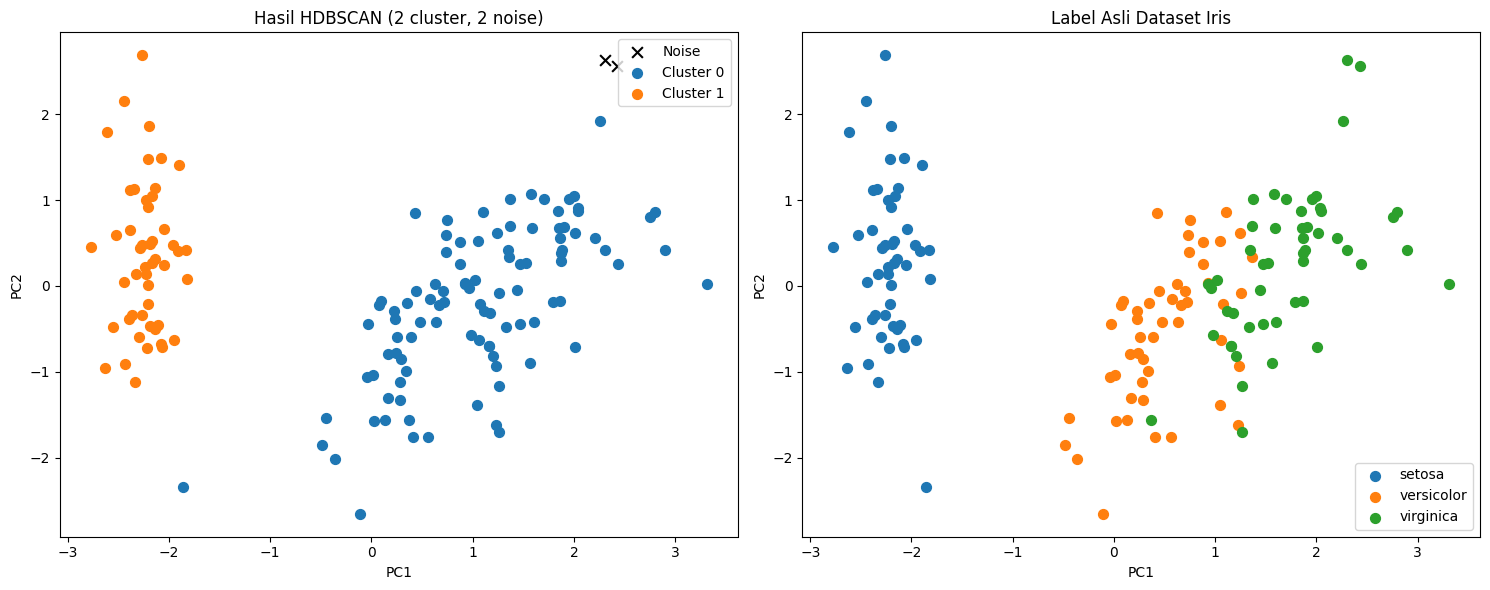

In [ ]:
# Visualisasi: reduksi 4 dimensi -> 2 dimensi dengan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print('Explained variance ratio PCA:', pca.explained_variance_ratio_, '| total:', pca.explained_variance_ratio_.sum())

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Hasil HDBSCAN (noise = hitam, tanda x)
for k in sorted(set(labels)):
    mask = labels == k
    if k == -1:
        axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], c='black', marker='x', s=60, label='Noise')
    else:
        axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], s=50, label=f'Cluster {k}')
axes[0].set_title(f'Hasil HDBSCAN ({n_cluster} cluster, {n_noise} noise)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend()

# Label asli
for k, name in enumerate(iris.target_names):
    mask = y_true == k
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], s=50, label=name)
axes[1].set_title('Label Asli Dataset Iris')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend()

plt.tight_layout()
plt.show()

### Soal 4 - Analisis: Apakah Hasil HDBSCAN Sesuai dengan Label Asli?

In [ ]:
# Tabel silang label asli vs hasil cluster
print(pd.crosstab(pd.Series([iris.target_names[i] for i in y_true], name='Label asli'),
                  pd.Series(labels, name='Cluster HDBSCAN')))

print('\nAdjusted Rand Index (ARI):', adjusted_rand_score(y_true, labels))

Cluster HDBSCAN  -1   0   1
Label asli                 
setosa            0   1  49
versicolor        0  50   0
virginica         2  48   0

Adjusted Rand Index (ARI): 0.539408633653917


**Analisis:**

Hasil HDBSCAN **hanya sebagian sesuai** dengan label asli:
- HDBSCAN membentuk **2 cluster** dan **2 noise**, padahal label aslinya ada 3 spesies.
- **Iris setosa** hampir seluruhnya (49 dari 50) masuk ke satu cluster tersendiri. Spesies ini memang terpisah jauh dari dua spesies lain (terutama dari ukuran kelopak/petal), sehingga mudah dikenali.
- **Iris versicolor** dan **Iris virginica** digabung menjadi **satu cluster**. Pada plot PCA kedua spesies ini saling bersinggungan tanpa celah kepadatan yang jelas, dan HDBSCAN hanya memisahkan kelompok yang dipisahkan oleh daerah berkepadatan rendah. Karena itu keduanya dianggap satu kelompok padat.
- Titik noise adalah data di pinggiran yang kepadatannya rendah.

Nilai **Adjusted Rand Index ±0,54** (1 = sama persis, 0 = acak) menegaskan kesesuaiannya hanya sedang. Jadi HDBSCAN berhasil menemukan struktur alami data (setosa vs non-setosa), tetapi tidak bisa membedakan versicolor dan virginica karena secara kepadatan keduanya memang tidak terpisah.